# 03 · Logistic Regression model building

This notebook builds the first model track using the confirmed target `diagnosis` (`M` is the positive class). It excludes the record ID and the all-empty `Unnamed: 32` field. Preprocessing is kept inside a scikit-learn pipeline so imputation and scaling are fitted only on training folds.

**Predeclared primary metric:** malignant-class recall. Secondary metrics are precision, F1, and ROC-AUC. The model is for educational research and is not a clinical diagnostic tool.

**Validation design:** hold out a stratified 20% test split before model selection. Split the remaining 80% into training and validation partitions (60%/20% of all rows). Select hyperparameters using 5-fold stratified cross-validation on the training partition only. Use validation once for a final development check and baseline comparison. Notebook 4 will load the exported pipeline and evaluate on the untouched test partition without retraining.

**Search budget declared before fitting:** 12 Logistic Regression configurations (6 values of `C` × 2 class-weight choices), each evaluated in 5 stratified folds: at most 60 candidate fits. Include one `most_frequent` DummyClassifier baseline. The primary selection criterion is mean cross-validation malignant recall; ties are resolved by GridSearchCV’s first-best rule over the declared ascending `C` grid, favoring stronger regularization. No search expansion after seeing results.

The dataset has 569 rows with 357 benign and 212 malignant cases. Its size supports a compact classical-model study, but estimates can vary with the split. EDA showed strong correlations among size-related features, so coefficient magnitudes will not be treated as independent measures of feature importance.

In [1]:
from pathlib import Path
import json
import platform
import random
from datetime import datetime, timezone

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
cwd = Path.cwd().resolve()
REPO_ROOT = next((candidate for candidate in [cwd, *cwd.parents]
                  if (candidate / 'data/raw/Raw_Breast_Cancer_Data.csv').exists()), None)
if REPO_ROOT is None:
    raise FileNotFoundError('Could not locate repository data/raw/Raw_Breast_Cancer_Data.csv from the notebook working directory.')
DATA_PATH = REPO_ROOT / 'data/raw/Raw_Breast_Cancer_Data.csv'
MODEL_DIR = REPO_ROOT / 'models/Logistic_Regression'
TARGET = 'diagnosis'
ID_COLUMN = 'id'
POSITIVE_LABEL = 'M'
LABEL_TO_INT = {'B': 0, 'M': 1}
print(f'Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__} | scikit-learn {sklearn.__version__}')
print('Global random seed:', SEED)

Python 3.13.3 | pandas 3.0.5 | NumPy 2.5.2 | scikit-learn 1.9.0
Global random seed: 42


In [2]:
df_raw = pd.read_csv(DATA_PATH)
empty_columns = df_raw.columns[df_raw.isna().all()].tolist()
df = df_raw.drop(columns=empty_columns).copy()
X = df.drop(columns=[TARGET, ID_COLUMN])
y = df[TARGET].map(LABEL_TO_INT)
if y.isna().any():
    raise ValueError('Unexpected or missing diagnosis label; inspect the source data before modeling.')
if set(y.unique()) != {0, 1}:
    raise ValueError('Expected both benign (B) and malignant (M) classes.')
print('Dataset shape after excluding all-empty field:', df.shape)
print('Predictor count:', X.shape[1])
print('Target counts (0=benign, 1=malignant):')
display(y.value_counts().sort_index().rename(index={0: 'B (benign)', 1: 'M (malignant)'}).to_frame('count'))
print('Missing predictor cells:', int(X.isna().sum().sum()))
print('Excluded all-empty columns:', empty_columns)

Dataset shape after excluding all-empty field: (569, 32)
Predictor count: 30
Target counts (0=benign, 1=malignant):


,count
diagnosis,
B (benign),357
M (malignant),212


Missing predictor cells: 0
Excluded all-empty columns: ['Unnamed: 32']


In [3]:
# Create three non-overlapping stratified partitions: 60% train, 20% validation, 20% test.
all_idx = np.arange(len(y))
dev_idx, test_idx = train_test_split(
    all_idx, test_size=0.20, random_state=SEED, stratify=y)
train_idx, val_idx = train_test_split(
    dev_idx, test_size=0.25, random_state=SEED, stratify=y.iloc[dev_idx])
assert not (set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx) or set(val_idx) & set(test_idx))
X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]
print(f'Train: {len(train_idx)} | Validation: {len(val_idx)} | Held-out test: {len(test_idx)}')
for split_name, split_y in [('train', y_train), ('validation', y_val), ('test', y_test)]:
    print(f'{split_name} class proportions: ' + split_y.value_counts(normalize=True).sort_index().round(3).to_dict().__str__())

Train: 341 | Validation: 114 | Held-out test: 114
train class proportions: {0: 0.628, 1: 0.372}
validation class proportions: {0: 0.623, 1: 0.377}
test class proportions: {0: 0.632, 1: 0.368}


## Baseline and scoring

The `most_frequent` baseline predicts the majority class from the training labels. It is a transparent reference point, not a useful screening model by design. We evaluate it on validation data and use malignant recall as the primary comparison measure. The test partition remains untouched.

In [4]:
def metric_row(y_true, y_pred, y_score=None):
    result = {
        'malignant_recall': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        'precision': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'f1': f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        'accuracy': accuracy_score(y_true, y_pred),
    }
    result['roc_auc'] = roc_auc_score(y_true, y_score) if y_score is not None else np.nan
    return result

baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
baseline_val_pred = baseline.predict(X_val)
baseline_val_score = baseline.predict_proba(X_val)[:, list(baseline.classes_).index(1)] if 1 in baseline.classes_ else None
baseline_val_metrics = metric_row(y_val, baseline_val_pred, baseline_val_score)
display(pd.DataFrame([baseline_val_metrics], index=['DummyClassifier (validation)']))
print('Baseline predicts one class only; zero malignant recall is expected from this strategy.')

,malignant_recall,precision,f1,accuracy,roc_auc
DummyClassifier (validation),0.0,0.0,0.0,0.622807,0.5


Baseline predicts one class only; zero malignant recall is expected from this strategy.


## Logistic Regression search

All candidate preprocessing is fitted within each training fold. `StandardScaler` is important for regularized Logistic Regression because the measured predictors have different units and scales. The median imputer is included as a train-fitted safeguard; it will be a no-op if the selected predictors have no missing values. `class_weight` tests whether balancing class penalties helps the predeclared malignant-recall objective.

In [5]:
pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(solver='lbfgs', max_iter=5000, random_state=SEED)),
])
C_VALUES = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
CLASS_WEIGHTS = [None, 'balanced']
param_grid = {
    'model__C': C_VALUES,
    'model__class_weight': CLASS_WEIGHTS,
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='recall',
    cv=cv,
    refit=True,
    return_train_score=True,
    n_jobs=-1,
    error_score='raise',
)
search.fit(X_train, y_train)
assert len(search.cv_results_['params']) == 12
print('Configurations evaluated:', len(search.cv_results_['params']))
print('Fold fits for candidate models:', len(search.cv_results_['params']) * cv.get_n_splits())
print('Selected parameters (by mean 5-fold malignant recall):', search.best_params_)
print('Best mean CV malignant recall:', round(search.best_score_, 4))

Configurations evaluated: 12
Fold fits for candidate models: 60
Selected parameters (by mean 5-fold malignant recall): {'model__C': 0.1, 'model__class_weight': 'balanced'}
Best mean CV malignant recall: 0.9609


In [6]:
# Save a structured experiment log with one row per evaluated configuration.
run_timestamp = datetime.now(timezone.utc).isoformat()
cv_results = pd.DataFrame(search.cv_results_)
experiment_log = pd.DataFrame({
    'model_name': 'LogisticRegression',
    'C': [p['model__C'] for p in search.cv_results_['params']],
    'class_weight': [str(p['model__class_weight']) for p in search.cv_results_['params']],
    'primary_metric': 'malignant_recall',
    'evaluation_split': '5-fold stratified CV on training partition',
    'mean_cv_malignant_recall': search.cv_results_['mean_test_score'],
    'std_cv_malignant_recall': search.cv_results_['std_test_score'],
    'mean_cv_train_recall': search.cv_results_['mean_train_score'],
    'run_timestamp_utc': run_timestamp,
})
MODEL_DIR.mkdir(parents=True, exist_ok=True)
log_path = MODEL_DIR / 'experiment_log.csv'
experiment_log.to_csv(log_path, index=False)
display(experiment_log.sort_values(['mean_cv_malignant_recall', 'std_cv_malignant_recall'], ascending=[False, True]))
print('Experiment log saved to:', log_path)

,model_name,C,class_weight,primary_metric,evaluation_split,mean_cv_malignant_recall,std_cv_malignant_recall,mean_cv_train_recall,run_timestamp_utc
5,LogisticRegression,0.100,balanced,malignant_recall,5-fold stratified CV on training partition,0.960923,0.024337,0.974413,2026-09-27T01:04:08.809043+00:00
7,LogisticRegression,1.000,balanced,malignant_recall,5-fold stratified CV on training partition,0.953231,0.037566,0.980295,2026-09-27T01:04:08.809043+00:00
8,LogisticRegression,10.000,None,malignant_recall,5-fold stratified CV on training partition,0.952923,0.029378,0.988177,2026-09-27T01:04:08.809043+00:00
9,LogisticRegression,10.000,balanced,malignant_recall,5-fold stratified CV on training partition,0.952923,0.029378,0.992118,2026-09-27T01:04:08.809043+00:00
4,LogisticRegression,0.100,None,malignant_recall,5-fold stratified CV on training partition,0.945538,0.051995,0.956688,2026-09-27T01:04:08.809043+00:00
10,LogisticRegression,100.000,None,malignant_recall,5-fold stratified CV on training partition,0.945231,0.057741,1.000000,2026-09-27T01:04:08.809043+00:00
6,LogisticRegression,1.000,None,malignant_recall,5-fold stratified CV on training partition,0.937538,0.039303,0.974393,2026-09-27T01:04:08.809043+00:00
11,LogisticRegression,100.000,balanced,malignant_recall,5-fold stratified CV on training partition,0.937231,0.057912,1.000000,2026-09-27T01:04:08.809043+00:00
3,LogisticRegression,0.010,balanced,malignant_recall,5-fold stratified CV on training partition,0.922154,0.100185,0.950747,2026-09-27T01:04:08.809043+00:00
1,LogisticRegression,0.001,balanced,malignant_recall,5-fold stratified CV on training partition,0.875077,0.094829,0.879984,2026-09-27T01:04:08.809043+00:00


Experiment log saved to: C:\Projects_Tracking\Breast_Cancer_Prediction\models\Logistic_Regression\experiment_log.csv


## Validation check and overfitting review

The selected configuration is chosen from training-only cross-validation. The validation partition is now used once to compare the tuned model with the baseline. Report train-fold versus held-out-fold recall from the experiment log as a rough overfitting diagnostic; large gaps or unstable fold scores call for caution. Do not select another configuration by repeatedly inspecting validation performance.

,malignant_recall,precision,f1,accuracy,roc_auc
DummyClassifier,0.000000,0.000000,0.000000,0.622807,0.500000
LogisticRegression (CV-selected),0.953488,0.953488,0.953488,0.964912,0.995414


Primary-metric validation difference (LR minus baseline): 0.9535


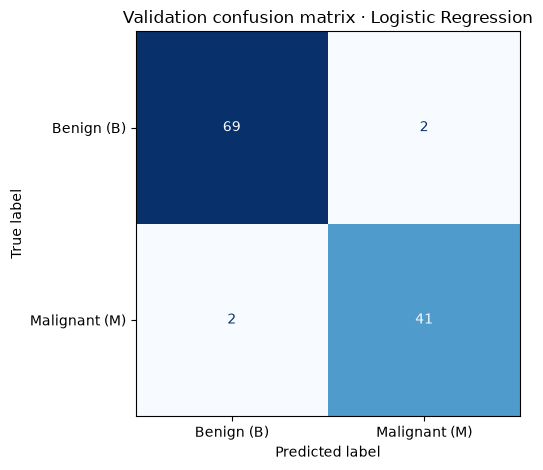

In [7]:
selected_pipeline = search.best_estimator_
val_pred = selected_pipeline.predict(X_val)
val_score = selected_pipeline.predict_proba(X_val)[:, list(selected_pipeline.classes_).index(1)]
selected_val_metrics = metric_row(y_val, val_pred, val_score)
comparison = pd.DataFrame(
    [baseline_val_metrics, selected_val_metrics],
    index=['DummyClassifier', 'LogisticRegression (CV-selected)'])
display(comparison)
print('Primary-metric validation difference (LR minus baseline):',
      round(selected_val_metrics['malignant_recall'] - baseline_val_metrics['malignant_recall'], 4))
ConfusionMatrixDisplay.from_predictions(
    y_val, val_pred, labels=[0, 1], display_labels=['Benign (B)', 'Malignant (M)'],
    cmap='Blues', colorbar=False)
plt.title('Validation confusion matrix · Logistic Regression')
plt.tight_layout()
plt.show()

In [8]:
# Refit the selected, fixed configuration on train + validation for final held-out testing.
# This does not use test features or labels.
X_development = pd.concat([X_train, X_val], axis=0)
y_development = pd.concat([y_train, y_val], axis=0)
final_pipeline = search.best_estimator_
final_pipeline.fit(X_development, y_development)
model_path = MODEL_DIR / 'logistic_regression_pipeline.joblib'
joblib.dump(final_pipeline, model_path)
metadata = {
    'model': 'LogisticRegression',
    'target': TARGET,
    'positive_label': POSITIVE_LABEL,
    'label_mapping': LABEL_TO_INT,
    'features': X.columns.tolist(),
    'excluded_columns': [ID_COLUMN] + empty_columns,
    'selected_parameters': search.best_params_,
    'primary_metric': 'malignant_recall',
    'selection_metric': 'mean 5-fold stratified CV malignant recall on training partition',
    'seed': SEED,
    'split_sizes': {'train': int(len(train_idx)), 'validation': int(len(val_idx)), 'test': int(len(test_idx))},
    'test_partition_note': 'Held out for Notebook 4; not used for fitting or model selection.',
    'search_budget': {'configurations': 12, 'folds': 5, 'candidate_fits_max': 60},
}
metadata_path = MODEL_DIR / 'model_metadata.json'
metadata_path.write_text(json.dumps(metadata, indent=2), encoding='utf-8')
print('Final pipeline saved to:', model_path)
print('Metadata saved to:', metadata_path)
print('Test split was not evaluated in this notebook.')

Final pipeline saved to: C:\Projects_Tracking\Breast_Cancer_Prediction\models\Logistic_Regression\logistic_regression_pipeline.joblib
Metadata saved to: C:\Projects_Tracking\Breast_Cancer_Prediction\models\Logistic_Regression\model_metadata.json
Test split was not evaluated in this notebook.


## Results, conclusion, and limitations

The 12-row experiment log selected `C=0.1` with `class_weight='balanced'`. Its training-only five-fold mean malignant recall was **0.9609** (fold standard deviation **0.0243**); mean training-fold recall was **0.9744**, a modest train/CV gap of about **0.0135**. The next-highest mean CV recall was 0.9532 (`C=1.0`, balanced), so the selected configuration followed the predeclared primary metric.

On the one-time validation check, Logistic Regression reached **0.9535 malignant recall**, **0.9535 precision**, **0.9535 F1**, **0.9649 accuracy**, and **0.9954 ROC-AUC**. The majority-class DummyClassifier had **0.0000 malignant recall**, **0.0000 precision/F1**, **0.6228 accuracy**, and **0.5000 ROC-AUC**. The validation confusion matrix corresponds to 2 false negatives and 2 false positives among 114 validation records. These are validation results, not final test results. The pipeline and metadata were saved, with the 114-row test partition reserved for Notebook 4.

**Conclusion:** this configuration is a promising development candidate under the declared recall-first criterion. It is not yet selected as the final model; that depends on a single held-out test evaluation and the limits below. The model has not been evaluated externally or clinically.

**Limitations:** the dataset has only 569 curated records, and validation estimates can vary with the split. One validation partition and five training folds do not establish robustness. The high ROC-AUC and validation scores may reflect this dataset's source and measurement process. The false-negative count is small but still consequential. The high correlations among size-related predictors make individual coefficients hard to interpret as separate effects. No patient demographics, clinical context, acquisition sites, or external cohort are available for subgroup or distribution-shift assessment. The test set must remain unused until Notebook 4; do not tune to improve its score.